# Neighborhoods change a summary

**Spatial methods · 15–25 minutes · synthetic methods edition**

A 90-element browser spatial-analysis collection describes compact synthetic notebooks and avoids heavy native GIS dependencies.

**Learning question:** How does widening a neighborhood change an invented local peak?

This original index activity is **synthetic teaching analysis**. It uses invented values or authored metadata, no real people or sensitive locations, no remote APIs, and no AI model calls. It is a small companion to the source project, not a reproduction of that project's full course.

![Learning workflow](../../assets/capabilities.svg)

Original atlas diagram, James L. Tobias and contributors, CC BY 4.0; see [asset provenance](../../visual-provenance.ipynb).


## Predict before running

Calculate focal means along five equally spaced fictional cells. Compare radius-one and radius-two index neighborhoods. At the ends, average only existing cells and print the denominator for each window. These fixtures have no missing values. Calculations require complete finite numeric values and a nonnegative integer focal radius; define a missing-data rule before introducing missing data.

Write a prediction and one assumption you would need to check. Run cells in order with **Shift+Enter**, or **Run → Run All Cells**. The next cell defines only local SVG display helpers; the following cell performs the analysis. Every graphic also prints its values as a text alternative.


In [1]:
from IPython.display import SVG, display
from html import escape

def svg(body, title, description, width=760, height=330):
    label = escape(title, quote=True)
    display(SVG(f'<svg xmlns="http://www.w3.org/2000/svg" viewBox="0 0 {width} {height}" role="img" aria-label="{label}"><title>{escape(title)}</title><desc>{escape(description)}</desc><rect width="100%" height="100%" fill="#f5f5ef" rx="12"/>{body}</svg>'))

def bars(values, title, unit):
    print(title + ' | ' + unit + ':', {k:round(v,3) for k,v in values.items()})
    n = len(values)
    height = max(250, 82 + n*36)
    maximum = max(max(values.values()), 1)
    body = f'<text x="22" y="30" font-family="sans-serif" font-size="18" fill="#123c45">{escape(title)}</text>'
    for i,(key,value) in enumerate(values.items()):
        y=58+i*36
        body += f'<text x="22" y="{y+17}" font-family="sans-serif" font-size="13">{escape(str(key))}</text><rect x="205" y="{y}" width="{max(0,value)/maximum*440:.2f}" height="23" rx="3" fill="#16756b"/><text x="{213+max(0,value)/maximum*440:.2f}" y="{y+17}" font-family="sans-serif" font-size="13">{value:.2f}</text>'
    body += f'<text x="205" y="{height-15}" font-family="sans-serif" font-size="12">zero baseline · {escape(unit)}</text>'
    svg(body, title, 'Values are printed as a text alternative; consult the chart title for data status.', height=height)

def grid(values, columns, title):
    print(title + ':', [round(v,3) for v in values])
    maximum = max(max(values),1)
    size = 54
    body = f'<text x="22" y="30" font-family="sans-serif" font-size="18">{escape(title)}</text>'
    for i,v in enumerate(values):
        x=25+(i%columns)*size; y=52+(i//columns)*size
        light=92-50*v/maximum
        body += f'<rect x="{x}" y="{y}" width="50" height="50" fill="hsl(169,45%,{light:.1f}%)" stroke="#123c45"/><text x="{x+25}" y="{y+29}" text-anchor="middle" font-family="sans-serif" font-size="14" fill="#061c21">{v:.1f}</text>'
    svg(body,title,'Synthetic grid with values printed in each cell; no actual boundaries.',height=max(220,70+((len(values)+columns-1)//columns)*size))

def lines(series, title, xunit, yunit):
    print(title + ':', {k:[round(v,3) for v in vs] for k,vs in series.items()})
    maximum=max(max(vs) for vs in series.values()) or 1
    body=f'<text x="22" y="30" font-family="sans-serif" font-size="18">{escape(title)}</text><path d="M55 55V265H710" fill="none" stroke="#123c45"/>'
    for j,(name,vs) in enumerate(series.items()):
        color=['#16756b','#a34712','#41449c'][j%3]
        pts=' '.join(f'{55+i*650/max(1,len(vs)-1):.1f},{265-v*200/maximum:.1f}' for i,v in enumerate(vs))
        body+=f'<polyline points="{pts}" fill="none" stroke="{color}" stroke-width="3"/><text x="{60+j*220}" y="310" font-family="sans-serif" font-size="13" fill="{color}">{escape(name)}</text>'
    body+=f'<text x="55" y="288" font-family="sans-serif" font-size="12">{escape(xunit)} → · {escape(yunit)} ↑ · y starts at zero</text>'
    svg(body,title,'Synthetic series; printed values are the text alternative.')


Synthetic cells in line order: [1, 1, 10, 1, 1]
Radius 1 denominators: [2, 3, 3, 3, 2] ; radius 2 denominators: [3, 4, 5, 4, 3]
Synthetic focal means on a line: {'raw cells': [1, 1, 10, 1, 1], 'radius 1 mean': [1.0, 4.0, 4.0, 4.0, 1.0], 'radius 2 mean': [4.0, 3.25, 2.8, 3.25, 4.0]}


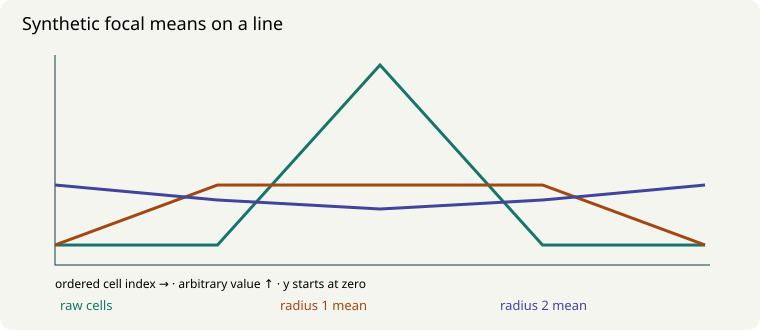

In [2]:
values = [1, 1, 10, 1, 1]
def focal_mean(values, radius):
    windows = [values[max(0, i-radius):min(len(values), i+radius+1)] for i in range(len(values))]
    return [sum(window)/len(window) for window in windows], [len(window) for window in windows]
near, near_n = focal_mean(values, 1)
wide, wide_n = focal_mean(values, 2)
print('Synthetic cells in line order:', values)
print('Radius 1 denominators:', near_n, '; radius 2 denominators:', wide_n)
lines({'raw cells':values, 'radius 1 mean':near, 'radius 2 mean':wide}, 'Synthetic focal means on a line', 'ordered cell index', 'arbitrary value')


## Interpret the result

The central value falls from 10 to 4 with radius one and to 2.8 with radius two. The radius-two means are [4, 3.25, 2.8, 3.25, 4]: the truncated endpoint windows have only three cells and produce the highest smoothed values, 4. Their overall mean is 3.46, whereas the raw mean is 2.8; truncated-window smoothing need not preserve the overall mean. Smoothing and its boundary rule change the pattern; they do not show that the original observation was an error or that an effect extends to nearby places.

Name the result, the assumption producing it, and one conclusion it cannot support. These are not clinical findings, causal effects or live model outputs.

## Change one thing

Change the peak to an end cell. Compare truncated windows with a rule requiring a full window, and explain which boundary policy belongs in the map caption. This scaffold reports full-window means only at valid cell indices:

```python
radius = 2
valid_indices = list(range(radius, len(values)-radius))
full_means = [sum(values[i-radius:i+radius+1])/(2*radius+1) for i in valid_indices]
unavailable_indices = [i for i in range(len(values)) if i not in valid_indices]
print('Full-window indices and means:', list(zip(valid_indices, full_means)))
print('Unavailable indices (omitted):', unavailable_indices)
```

At radius two only index 2 has a full window. Report unavailable endpoints as omitted, rather than zero-filling them or passing None to the line helper. Any separate plot must preserve the actual valid cell indices.

Save a copy with **File → Save and Export Notebook As → Notebook** (or the file browser's Download command). Browser storage is local to this browser/profile; it is not a GitHub commit or shared database.


## Connect the idea

Compare this activity with another chapter on the same [learning path](../../index.ipynb). Keep the question, data status and interpretation visible when transferring a method.


## Sources, continuation and limits

**Source repository:** [JupyterLite-Spatial-Analysis](https://github.com/jltobias/JupyterLite-Spatial-Analysis).

**Source README:** [reviewed immutable version](https://github.com/jltobias/JupyterLite-Spatial-Analysis/blob/88007a32ab0ac970469af4b0c118209325a1989f/README.md); inspected 2026-11-01, commit `88007a32ab0a`. Repository content and linked works keep their original terms. Summaries and exercises here are newly authored.

The source describes 90 element notebooks plus an index, inspired by GISGeography's Periodic Table for Spatial Analysis. It documents numpy/pandas/matplotlib teaching examples and explicitly avoids compiled GIS stacks. No exact hosted launch URL is documented. This original line-grid activity imports no source notebooks, definitions, periodic-table artwork or datasets. See the separately attributed GISGeography source in the central references.

No exact published launch URL is documented in this README. Use the repository source; hosted availability is unverified.

**Runtime budget:** this default is fewer than 100 values and normally completes within seconds; allow 60 seconds per cell while first loading Python. Continue with the reviewed README's local JupyterLite build or GitHub Actions/Pages instructions. Its synthetic numpy/pandas/matplotlib notebooks avoid compiled GIS libraries; verify their behavior in the resulting browser build. No hosted launch URL is documented. [Reviewed source README](https://github.com/jltobias/JupyterLite-Spatial-Analysis/blob/88007a32ab0ac970469af4b0c118209325a1989f/README.md).

[Central references](../../references.ipynb) · [Contribute](../../contributor-guide.ipynb)
